# TC3-48 — Analisar relações temporais

**Objetivo:** avaliar diferenças e padrões entre os anos disponíveis na base consolidada, considerando o recorte do estudo: alunos da série 2 e o target `alfabetizado`.

## Relação com os notebooks anteriores

- **TC3-43:** forneceu o contexto da distribuição do target `alfabetizado`.
- **TC3-44 e TC3-45:** reforçaram a necessidade de considerar distribuição, valores ausentes e cobertura dos dados.
- **TC3-46:** investigou associações entre variáveis, incluindo a correlação elevada entre `proficiencia` e `alfabetizado`.
- **TC3-47:** comparou os resultados por município, UF e rede de ensino.

## Cuidados metodológicos

- O target `alfabetizado` será utilizado conforme recebido na base, sem recalcular sua classificação.
- A análise será restrita à série 2 quando a coluna de série estiver disponível.
- A média do target binário pode ser interpretada como proporção da classe 1.
- Diferenças entre anos são descritivas e não comprovam causalidade.
- É necessário verificar se os anos são comparáveis quanto à cobertura, à definição das variáveis e à composição dos registros.
- `id_aluno` não será utilizado para vinculação longitudinal individual: a estabilidade desse identificador entre anos não está validada para esta análise, e a documentação do Inep descreve a reestruturação dos microdados para reduzir riscos de identificação.
- As comparações temporais serão feitas por grupos agregados (por exemplo, município/ano, UF/ano e rede/ano), sem interpretar diferenças como acompanhamento dos mesmos estudantes.
- Se houver apenas dois anos, os resultados permitem comparar os períodos observados, mas não estabelecer uma tendência de longo prazo.

## 1. Preparação do ambiente

Utilizaremos Polars para consultar os arquivos Parquet e pandas/matplotlib/seaborn para apresentar tabelas e gráficos.

In [1]:
from pathlib import Path
import warnings

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)
sns.set_theme()

print("Polars:", pl.__version__)
print("Pandas:", pd.__version__)

Polars: 2.0.0
Pandas: 3.0.6


## 2. Localização e leitura dos arquivos

O código procura a pasta da base a partir do diretório atual e de seus diretórios pais. Se a estrutura local for diferente, ajuste `BASE_PATH` para apontar para a pasta `base_alunos_municipios_por_uf`.

In [2]:
NOME_PASTA_BASE = "base_alunos_municipios_por_uf"

candidatos_raiz = [Path.cwd(), *Path.cwd().parents]
BASE_PATH = None

for pasta in candidatos_raiz:
    candidato = pasta / "dados" / "consolidado" / NOME_PASTA_BASE
    if candidato.exists():
        BASE_PATH = candidato
        break

if BASE_PATH is None:
    # Alternativa: procura a pasta da base entre subpastas próximas do diretório atual.
    for pasta in candidatos_raiz[:3]:
        candidato = pasta / NOME_PASTA_BASE
        if candidato.exists():
            BASE_PATH = candidato
            break

if BASE_PATH is None:
    raise FileNotFoundError(
        "Não encontrei a pasta da base. Ajuste BASE_PATH manualmente para "
        "a pasta dados/consolidado/base_alunos_municipios_por_uf."
    )

arquivos_parquet = list(BASE_PATH.glob("sigla_uf=*/00000000.parquet"))

if not arquivos_parquet:
    arquivos_parquet = list(BASE_PATH.rglob("*.parquet"))

if not arquivos_parquet:
    raise FileNotFoundError(f"Nenhum arquivo Parquet encontrado em {BASE_PATH}")

lf = pl.scan_parquet([str(p) for p in arquivos_parquet])
schema = lf.collect_schema()
colunas = schema.names()

print("Pasta da base:", BASE_PATH)
print("Quantidade de arquivos Parquet:", len(arquivos_parquet))
print("Quantidade de colunas:", len(colunas))
print("Quantidade de registros:", lf.select(pl.len()).collect().item())

Pasta da base: c:\Users\sandr\POS-TECH\Fase 3\tech_challenge_3\dados\consolidado\base_alunos_municipios_por_uf
Quantidade de arquivos Parquet: 26
Quantidade de colunas: 49
Quantidade de registros: 3867999


## 3. Identificação das dimensões e indicadores

Esta etapa verifica quais colunas temporais e educacionais estão disponíveis, evitando assumir que todos os nomes existem em todas as versões da base.

In [3]:
def primeira_coluna(candidatas, disponiveis):
    return next((c for c in candidatas if c in disponiveis), None)

COL_ANO = primeira_coluna(
    ["ano_referencia", "ano", "ano_base", "ano_letivo", "nu_ano"],
    colunas
)
COL_SERIE = primeira_coluna(
    ["serie", "ano_escolar", "etapa", "etapa_ensino"],
    colunas
)
COL_TARGET = "alfabetizado" if "alfabetizado" in colunas else None
COL_PROFICIENCIA = "proficiencia" if "proficiencia" in colunas else None
COL_PRESENCA = "presenca" if "presenca" in colunas else None
COL_PREENCHIMENTO = "preenchimento_caderno" if "preenchimento_caderno" in colunas else None
COL_UF = primeira_coluna(["sigla_uf", "uf", "nome_uf"], colunas)
COL_MUNICIPIO = primeira_coluna(["id_municipio", "codigo_municipio", "cod_municipio"], colunas)
COL_REDE = primeira_coluna(["rede_descricao", "rede", "tipo_rede"], colunas)

display(pd.DataFrame([
    {"dimensao_ou_indicador": nome, "coluna_detectada": coluna, "disponivel": coluna is not None}
    for nome, coluna in [
        ("Ano de referência", COL_ANO),
        ("Série", COL_SERIE),
        ("Target alfabetizado", COL_TARGET),
        ("Proficiência", COL_PROFICIENCIA),
        ("Presença", COL_PRESENCA),
        ("Preenchimento do caderno", COL_PREENCHIMENTO),
        ("UF", COL_UF),
        ("Município", COL_MUNICIPIO),
        ("Rede de ensino", COL_REDE),
    ]
]))

if COL_ANO is None:
    raise ValueError(
        "Não foi encontrada uma coluna de ano reconhecida. Confira as colunas acima "
        "e ajuste a lista de candidatas em COL_ANO."
    )

if COL_TARGET is None:
    raise ValueError("A coluna 'alfabetizado' não foi encontrada na base.")

,dimensao_ou_indicador,coluna_detectada,disponivel
0,Ano de referência,ano_referencia,True
1,Série,serie,True
2,Target alfabetizado,alfabetizado,True
3,Proficiência,proficiencia,True
4,Presença,presenca,True
5,Preenchimento do caderno,preenchimento_caderno,True
6,UF,sigla_uf,True
7,Município,id_municipio,True
8,Rede de ensino,rede_descricao,True


## 4. Validar o recorte da série e a cobertura temporal

Quando a coluna de série existir, a análise será restrita à série 2. Em seguida, serão identificados os anos disponíveis e a quantidade de registros em cada ano.

In [4]:
lf_analise = lf

if COL_SERIE is not None:
    series_disponiveis = (
        lf.select(COL_SERIE)
          .drop_nulls()
          .unique()
          .sort(COL_SERIE)
          .collect()
    )
    print("Valores encontrados na coluna de série:")
    display(series_disponiveis.to_pandas())

    valores_serie = series_disponiveis[COL_SERIE].to_list()
    if 2 in valores_serie:
        lf_analise = lf_analise.filter(pl.col(COL_SERIE) == 2)
        print("Análise restrita à série 2.")
    else:
        warnings.warn("O valor 2 não foi encontrado na coluna de série; confira o recorte antes de interpretar os resultados.")
else:
    print("Coluna de série não encontrada; o recorte não pôde ser validado automaticamente.")

cobertura_anos = (
    lf_analise.group_by(COL_ANO)
    .agg(pl.len().alias("quantidade_registros"))
    .sort(COL_ANO)
    .collect()
)

display(cobertura_anos.to_pandas())
print("Quantidade de anos distintos:", cobertura_anos.height)

# Cobertura territorial por ano: comparação agregada, sem vincular estudantes individualmente.
campos_cobertura = [COL_ANO]
if COL_UF is not None:
    campos_cobertura.append(COL_UF)
if COL_MUNICIPIO is not None:
    campos_cobertura.append(COL_MUNICIPIO)

if len(campos_cobertura) > 1:
    agregacoes_cobertura = [pl.len().alias("quantidade_registros")]
    if COL_UF is not None:
        agregacoes_cobertura.append(pl.col(COL_UF).n_unique().alias("ufs_distintas"))
    if COL_MUNICIPIO is not None:
        agregacoes_cobertura.append(pl.col(COL_MUNICIPIO).n_unique().alias("municipios_distintos"))
    cobertura_territorial = (
        lf_analise.group_by(COL_ANO)
        .agg(agregacoes_cobertura)
        .sort(COL_ANO)
        .collect()
        .to_pandas()
    )
    print("Cobertura territorial por ano:")
    display(cobertura_territorial)
else:
    print("Não há campos territoriais suficientes para resumir a cobertura por ano.")


Valores encontrados na coluna de série:


,serie
0,2


Análise restrita à série 2.


,ano_referencia,quantidade_registros
0,2023,1747439
1,2024,2120560


Quantidade de anos distintos: 2
Cobertura territorial por ano:


,ano_referencia,quantidade_registros,ufs_distintas,municipios_distintos
0,2023,1747439,23,4873
1,2024,2120560,26,5519


### Nota metodológica — identificador individual

Durante a investigação exploratória, observou-se que alguns valores de `id_aluno` aparecem associados a municípios diferentes em 2023 e 2024. Isso não será interpretado como mudança de município pelos estudantes. A documentação do Inep informa que os formatos dos microdados estão sendo reestruturados para suprimir a possibilidade de identificação de pessoas, em atendimento à LGPD; contudo, esse princípio geral não comprova, isoladamente, como o identificador específico foi gerado. Portanto, até validar sua estabilidade, `id_aluno` não será utilizado para cruzamentos longitudinais individuais. As análises deste notebook permanecem agregadas por ano e por dimensões compatíveis, como município, UF e rede.


## 5. Resumo anual dos indicadores

A tabela apresenta a quantidade de registros, a proporção da classe 1 do target e, quando disponíveis, as médias dos indicadores educacionais por ano.

In [5]:
agregacoes = [
    pl.len().alias("quantidade_registros"),
    pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
    pl.col(COL_TARGET).count().alias("target_validos"),
    pl.col(COL_TARGET).is_null().sum().alias("target_nulo"),
]

if COL_PROFICIENCIA is not None:
    agregacoes.extend([
        pl.col(COL_PROFICIENCIA).count().alias("proficiencia_validos"),
        pl.col(COL_PROFICIENCIA).mean().alias("proficiencia_media"),
        pl.col(COL_PROFICIENCIA).median().alias("proficiencia_mediana"),
        pl.col(COL_PROFICIENCIA).is_null().sum().alias("proficiencia_nula"),
    ])

if COL_PRESENCA is not None:
    agregacoes.extend([
        pl.col(COL_PRESENCA).count().alias("presenca_validos"),
        pl.col(COL_PRESENCA).mean().alias("presenca_media"),
    ])

if COL_PREENCHIMENTO is not None:
    agregacoes.extend([
        pl.col(COL_PREENCHIMENTO).count().alias("preenchimento_validos"),
        pl.col(COL_PREENCHIMENTO).mean().alias("preenchimento_caderno_medio"),
    ])

resumo_anual = (
    lf_analise.group_by(COL_ANO)
    .agg(agregacoes)
    .sort(COL_ANO)
    .collect()
    .to_pandas()
)

display(resumo_anual)

,ano_referencia,quantidade_registros,proporcao_alfabetizado,target_validos,target_nulo,proficiencia_validos,proficiencia_media,proficiencia_mediana,proficiencia_nula,presenca_validos,presenca_media,preenchimento_validos,preenchimento_caderno_medio
0,2023,1747439,0.502122,1747439,0,1502809,747.563828,752.147831,244630,1747439,0.860149,1747439,0.860007
1,2024,2120560,0.522088,2120560,0,1851852,749.042072,753.950000,268708,2120560,0.873726,2120560,0.873284


## 6. Evolução da proporção de registros na classe 1

O gráfico mostra a proporção anual de registros com `alfabetizado = 1`. Ele descreve os anos observados e não representa, por si só, o índice oficial de alfabetização.

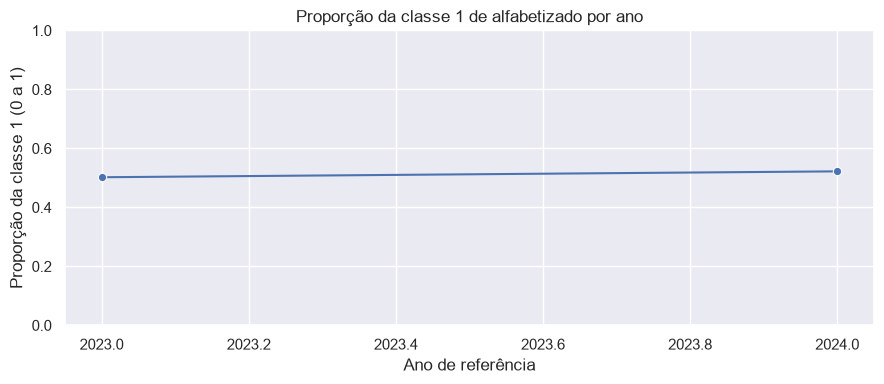

In [6]:
grafico_target = resumo_anual.dropna(subset=["proporcao_alfabetizado"]).copy()

if not grafico_target.empty:
    plt.figure(figsize=(9, 4))
    sns.lineplot(
        data=grafico_target,
        x=COL_ANO,
        y="proporcao_alfabetizado",
        marker="o"
    )
    plt.title("Proporção da classe 1 de alfabetizado por ano")
    plt.xlabel("Ano de referência")
    plt.ylabel("Proporção da classe 1 (0 a 1)")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
else:
    print("Não há valores válidos de alfabetizado para gerar o gráfico.")

## 7. Evolução da proficiência

Quando a variável estiver disponível, comparamos a média e a mediana da proficiência por ano. A comparação deve considerar eventuais mudanças de cobertura e de composição dos registros.

,ano_referencia,indicador,valor
0,2023,proficiencia_media,747.563828
1,2024,proficiencia_media,749.042072
2,2023,proficiencia_mediana,752.147831
3,2024,proficiencia_mediana,753.950000


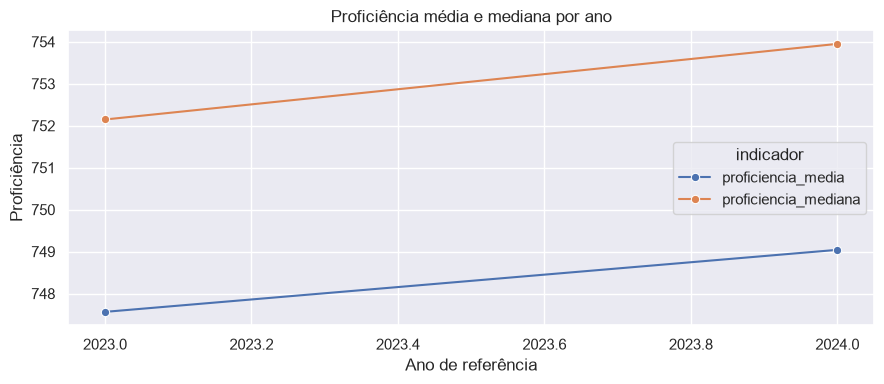

In [7]:
if COL_PROFICIENCIA is not None and "proficiencia_media" in resumo_anual.columns:
    proficiencia_long = resumo_anual.melt(
        id_vars=[COL_ANO],
        value_vars=[c for c in ["proficiencia_media", "proficiencia_mediana"] if c in resumo_anual.columns],
        var_name="indicador",
        value_name="valor"
    )

    display(proficiencia_long)

    plt.figure(figsize=(9, 4))
    sns.lineplot(
        data=proficiencia_long,
        x=COL_ANO,
        y="valor",
        hue="indicador",
        marker="o"
    )
    plt.title("Proficiência média e mediana por ano")
    plt.xlabel("Ano de referência")
    plt.ylabel("Proficiência")
    plt.tight_layout()
    plt.show()
else:
    print("A variável proficiencia não está disponível; gráfico não gerado.")

## 8. Variação entre anos consecutivos

A tabela calcula diferenças entre as linhas anuais ordenadas. Antes de interpretar como variação entre anos consecutivos, confirme que os anos são de fato consecutivos e que cobertura e definições são comparáveis. A variação da proporção é apresentada em pontos percentuais. Não é uma análise longitudinal dos mesmos alunos.

In [8]:
resumo_ordenado = resumo_anual.copy()

# Ordenação numérica quando os anos puderem ser convertidos para número.
resumo_ordenado["_ano_ordem"] = pd.to_numeric(resumo_ordenado[COL_ANO], errors="coerce")
if resumo_ordenado["_ano_ordem"].notna().all():
    resumo_ordenado = resumo_ordenado.sort_values("_ano_ordem")
else:
    resumo_ordenado = resumo_ordenado.sort_values(COL_ANO)

indicadores_variacao = [
    c for c in [
        "quantidade_registros",
        "proporcao_alfabetizado",
        "proficiencia_media",
        "proficiencia_mediana",
        "presenca_media",
        "preenchimento_caderno_medio",
    ]
    if c in resumo_ordenado.columns
]

variacoes = resumo_ordenado[[COL_ANO] + indicadores_variacao].copy()
for indicador in indicadores_variacao:
    variacoes[f"variacao_{indicador}"] = variacoes[indicador].diff()

if "variacao_proporcao_alfabetizado" in variacoes.columns:
    variacoes["variacao_proporcao_pontos_percentuais"] = (
        variacoes["variacao_proporcao_alfabetizado"] * 100
    )

display(variacoes.drop(columns=["_ano_ordem"], errors="ignore"))

,ano_referencia,quantidade_registros,proporcao_alfabetizado,proficiencia_media,proficiencia_mediana,presenca_media,preenchimento_caderno_medio,variacao_quantidade_registros,variacao_proporcao_alfabetizado,variacao_proficiencia_media,variacao_proficiencia_mediana,variacao_presenca_media,variacao_preenchimento_caderno_medio,variacao_proporcao_pontos_percentuais
0,2023,1747439,0.502122,747.563828,752.147831,0.860149,0.860007,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024,2120560,0.522088,749.042072,753.950000,0.873726,0.873284,373121.0,0.019966,1.478244,1.802169,0.013577,0.013278,1.996636


## 9. Comparação temporal por UF

Quando a coluna de UF estiver disponível, esta análise compara a proporção da classe 1 por UF e ano. O gráfico usa apenas os grupos observados; mudanças na quantidade de registros devem ser consideradas na interpretação.

,ano_referencia,sigla_uf,quantidade_registros,proporcao_alfabetizado
0,2023,AL,35503,0.410782
1,2023,AM,63055,0.405709
2,2023,AP,12349,0.373229
3,2023,BA,137724,0.315747
4,2023,CE,100349,0.806605
5,2023,ES,50482,0.604394
6,2023,GO,83741,0.583000
7,2023,MA,74958,0.507471
8,2023,MG,210107,0.545470
9,2023,MS,42199,0.420081


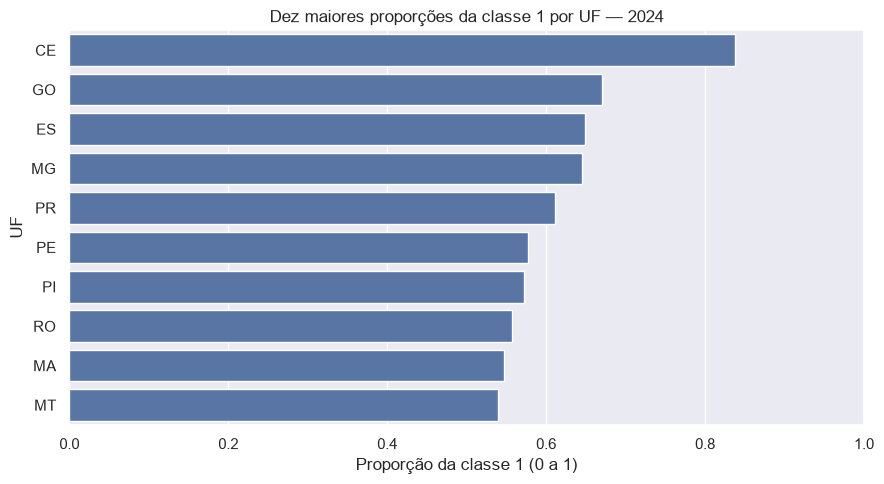

In [9]:
if COL_UF is not None:
    resumo_uf_ano = (
        lf_analise.group_by([COL_ANO, COL_UF])
        .agg([
            pl.len().alias("quantidade_registros"),
            pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
        ])
        .sort([COL_ANO, COL_UF])
        .collect()
        .to_pandas()
    )

    display(resumo_uf_ano.head(30))

    anos_lista = resumo_uf_ano[COL_ANO].dropna().unique().tolist()
    anos_numericos = pd.to_numeric(pd.Series(anos_lista), errors="coerce")
    if anos_numericos.notna().all():
        anos_lista = [x for _, x in sorted(zip(anos_numericos.tolist(), anos_lista))]
    else:
        anos_lista = sorted(anos_lista, key=lambda x: str(x))
    if len(anos_lista) > 0:
        ano_recente = anos_lista[-1]
        recorte_recente = resumo_uf_ano[resumo_uf_ano[COL_ANO] == ano_recente].copy()
        recorte_recente = recorte_recente.sort_values("proporcao_alfabetizado", ascending=False).head(10)

        plt.figure(figsize=(9, 5))
        sns.barplot(
            data=recorte_recente,
            x="proporcao_alfabetizado",
            y=COL_UF
        )
        plt.title(f"Dez maiores proporções da classe 1 por UF — {ano_recente}")
        plt.xlabel("Proporção da classe 1 (0 a 1)")
        plt.ylabel("UF")
        plt.xlim(0, 1)
        plt.tight_layout()
        plt.show()
else:
    print("Coluna de UF não encontrada; comparação temporal por UF não realizada.")

## 10. Comparação temporal por rede de ensino

Quando a coluna de rede estiver disponível, a tabela permite comparar proporções e volumes entre anos e redes. Se `rede_descricao` estiver disponível, ela será utilizada para facilitar a leitura.

In [10]:
if COL_REDE is not None:
    resumo_rede_ano = (
        lf_analise.group_by([COL_ANO, COL_REDE])
        .agg([
            pl.len().alias("quantidade_registros"),
            pl.col(COL_TARGET).mean().alias("proporcao_alfabetizado"),
        ])
        .sort([COL_ANO, COL_REDE])
        .collect()
        .to_pandas()
    )

    display(resumo_rede_ano)
else:
    print("Coluna de rede não encontrada; comparação temporal por rede não realizada.")

,ano_referencia,rede_descricao,quantidade_registros,proporcao_alfabetizado
0,2023,Estadual,155140,0.519930
1,2023,Municipal,1592299,0.500387
2,2024,Estadual,280258,0.537933
3,2024,Municipal,1840277,0.519673
4,2024,Privada,25,0.640000


## 11. Síntese dos achados

A síntese abaixo é preenchida a partir dos resultados calculados, sem atribuir causalidade. Os resultados devem ser interpretados à luz da cobertura e da comparabilidade dos anos.

In [13]:
anos_observados = cobertura_anos[COL_ANO].drop_nulls().to_list()
n_anos = len(anos_observados)

achados_temporais = []

achados_temporais.append({
    "tema": "Cobertura temporal",
    "observacao": f"Foram identificados {n_anos} anos distintos na coluna {COL_ANO}: {anos_observados}.",
    "limitacao": "A existência de vários anos não garante, por si só, que a cobertura e a composição dos registros sejam comparáveis."
})

if not resumo_anual.empty and resumo_anual["proporcao_alfabetizado"].notna().any():
    validos_target = resumo_anual.dropna(subset=["proporcao_alfabetizado"])
    ano_min = validos_target.loc[validos_target["proporcao_alfabetizado"].idxmin(), COL_ANO]
    ano_max = validos_target.loc[validos_target["proporcao_alfabetizado"].idxmax(), COL_ANO]
    min_pct = validos_target["proporcao_alfabetizado"].min() * 100
    max_pct = validos_target["proporcao_alfabetizado"].max() * 100
    achados_temporais.append({
        "tema": "Proporção do target",
        "observacao": f"A proporção anual da classe 1 variou de {min_pct:.2f}% ({ano_min}) a {max_pct:.2f}% ({ano_max}).",
        "limitacao": "A proporção corresponde à média do target binário na base, não necessariamente ao índice oficial calculado por outra metodologia."
    })

if "quantidade_registros" in resumo_anual.columns and len(resumo_anual) > 0:
    achados_temporais.append({
        "tema": "Volume de registros",
        "observacao": f"A quantidade de registros por ano variou de {int(resumo_anual['quantidade_registros'].min())} a {int(resumo_anual['quantidade_registros'].max())}.",
        "limitacao": "Variações de volume podem afetar a comparabilidade dos indicadores entre anos."
    })

achados_temporais.append({
    "tema": "Interpretação",
    "observacao": "As análises comparam indicadores agregados nos períodos observados, por ano e por grupos territoriais/administrativos disponíveis.",
    "limitacao": "Não foi realizado acompanhamento individual dos estudantes: a estabilidade de id_aluno entre anos não está validada. Diferenças temporais não comprovam causalidade e exigem avaliar cobertura, definições e disponibilidade das variáveis."
})

if n_anos < 3:
    achados_temporais.append({
        "tema": "Quantidade de períodos",
        "observacao": f"A base contém {n_anos} ano(s) distinto(s) identificado(s).",
        "limitacao": "Com menos de três períodos, a análise não deve ser descrita como uma tendência de longo prazo."
    })

display(pd.DataFrame(achados_temporais))

,tema,observacao,limitacao
0,Cobertura temporal,"Foram identificados 2 anos distintos na coluna ano_referencia: [2023, 2024].","A existência de vários anos não garante, por si só, que a cobertura e a composição dos registros sejam comparáveis."
1,Proporção do target,A proporção anual da classe 1 variou de 50.21% (2023) a 52.21% (2024).,"A proporção corresponde à média do target binário na base, não necessariamente ao índice oficial calculado por outra..."
2,Volume de registros,A quantidade de registros por ano variou de 1747439 a 2120560.,Variações de volume podem afetar a comparabilidade dos indicadores entre anos.
3,Interpretação,"As análises comparam indicadores agregados nos períodos observados, por ano e por grupos territoriais/administrativo...",Não foi realizado acompanhamento individual dos estudantes: a estabilidade de id_aluno entre anos não está validada....
4,Quantidade de períodos,A base contém 2 ano(s) distinto(s) identificado(s).,"Com menos de três períodos, a análise não deve ser descrita como uma tendência de longo prazo."


## 12. Conclusão

Após executar as células, revise os resultados anuais, as diferenças observadas na proporção do target e nos indicadores educacionais, bem como as variações de volume e cobertura.

A interpretação deve se limitar aos anos e grupos efetivamente observados. Diferenças temporais são descritivas e não comprovam causalidade. A proporção da classe 1 de `alfabetizado` deve ser distinguida do índice oficial de alfabetização caso as metodologias de cálculo não sejam equivalentes.

As comparações deste notebook são agregadas por ano e, quando disponível, por UF, município ou rede. O campo `id_aluno` não é usado para vinculação longitudinal individual, pois sua estabilidade entre anos não está validada para esta análise. Antes de concluir, confira se os anos comparados possuem cobertura e definições compatíveis e registre limitações relevantes para as próximas etapas do projeto.

A cobertura territorial também variou entre os períodos: foram identificadas 23 UFs e 4.873 municípios em 2023, frente a 26 UFs e 5.519 municípios em 2024. Essa diferença deve ser considerada na interpretação das variações observadas, pois parte dos resultados pode refletir mudanças na cobertura e na composição dos registros.